# Baseline: SVM (RBF kernel)

One `SVC` per label set, trained on the training split and scored with weighted F1 on the test split.

In [2]:
import tarfile
from pathlib import Path
import pandas as pd

def find_data_dir(name="data", start=None):
    """Search the current folder and its parents for a folder called `name`."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        candidate = folder / name
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError(f"No '{name}' folder found above {start}")

DATA_DIR = find_data_dir()
print("DATA_DIR:", DATA_DIR)

# Find the archive (.gz, .tar.gz or .tgz) without hardcoding the exact name
src = next(DATA_DIR.glob("moanna_training_data*"), None)
if src is None:
    raise FileNotFoundError(f"No moanna_training_data* file in {DATA_DIR}")
print("Archive:", src)

out_dir = DATA_DIR / "extracted"
if not out_dir.exists():                      
    with tarfile.open(src, "r:*") as tar:     
        tar.extractall(out_dir)

# Locate the extracted files wherever they ended up
dat_path = next(out_dir.rglob("moanna_training_data.tsv"))
lab_path = next(out_dir.rglob("moanna_training_label.tsv"))


DATA_DIR: C:\Users\ASUS\Desktop\Github Qeue\moanna-reimplementation\data
Archive: C:\Users\ASUS\Desktop\Github Qeue\moanna-reimplementation\data\moanna_training_data.gz


In [3]:
dat_df_val_path = next(out_dir.rglob("moanna_validation_data.tsv"))
lab_df_val_path = next(out_dir.rglob("moanna_validation_label.tsv"))

dat_df_test_path = next(out_dir.rglob("moanna_testing_data.tsv"))
lab_df_test_path = next(out_dir.rglob("moanna_testing_label.tsv"))

In [4]:
import pandas as pd
import numpy as np
from sklearn import preprocessing

In [5]:
dat_df = pd.read_csv(dat_path, sep="\t", index_col=0)
lab_df = pd.read_csv(lab_path, sep="\t", index_col=0)

dat_df_val = pd.read_csv(dat_df_val_path, sep="\t", index_col=0)
lab_df_val = pd.read_csv(lab_df_val_path, sep="\t", index_col=0)

dat_df_test = pd.read_csv(dat_df_test_path, sep="\t", index_col=0)
lab_df_test = pd.read_csv(lab_df_test_path, sep="\t", index_col=0)

In [6]:
feature_df = dat_df[dat_df.columns.tolist()]
X_train = np.asarray(feature_df)
X_train[0:5]

array([[ 2.12264563, -0.12209115,  0.63850882, ...,  0.        ,
         0.        ,  0.        ],
       [-0.56115416,  0.50813902,  1.64774974, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.04620343,  0.15135048,  0.25837112, ...,  0.        ,
         0.        ,  0.        ],
       [ 0.1608107 , -1.77757804, -0.85055661, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.5296817 , -0.34016732, -0.12719854, ...,  0.        ,
         0.        ,  0.        ]], shape=(5, 46776))

In [7]:
y_list_train = []
for column in lab_df.columns:
    y_list_train.append(np.asarray(lab_df[column].tolist()))
print(type(y_list_train[0]))
print(y_list_train[0][:5])

<class 'numpy.ndarray'>
[1 0 1 0 1]


In [8]:
feature_df = dat_df_test[dat_df_test.columns.tolist()]
X_test = np.asarray(feature_df)
X_test[0:5]

array([[-0.15371285, -0.28378515, -0.21165923, ...,  0.        ,
         0.        ,  0.        ],
       [-0.52256884,  0.51027408, -0.04365494, ...,  0.        ,
         0.        ,  0.        ],
       [ 0.04554269, -0.28378515,  0.30862874, ...,  0.        ,
         0.        ,  0.        ],
       [-0.05053091, -0.28378515, -0.02645278, ...,  0.        ,
         0.        ,  0.        ],
       [-0.20058344, -0.28378515, -0.21516146, ...,  0.        ,
         0.        ,  0.        ]], shape=(5, 46776))

In [9]:
y_list_test = []
for column in lab_df_test.columns:
    y_list_test.append(np.asarray(lab_df_test[column].tolist()))

In [10]:
print ('Train set:', X_train.shape,  y_list_train[0].shape)
print ('Test set:', X_test.shape,  y_list_test[0].shape)

Train set: (1182, 46776) (1182,)
Test set: (631, 46776) (631,)


In [11]:
from sklearn import svm
from sklearn.metrics import f1_score, accuracy_score

label_names = lab_df.columns.tolist()

rows = []
for name, y_train, y_test in zip(label_names, y_list_train, y_list_test):
    clf = svm.SVC()
    clf.fit(X_train, y_train)
    yhat = clf.predict(X_test)

    rows.append({
        'Label': name,
        'F1 (weighted)': f1_score(y_test, yhat, average='weighted'),
        'Accuracy': accuracy_score(y_test, yhat),
    })

results_df = pd.DataFrame(rows).set_index('Label')
results_df.loc['Average'] = results_df.mean()

styled = (results_df * 100).style \
    .format("{:.2f}") \
    .highlight_max(subset=pd.IndexSlice[label_names, :], axis=0, color='lightgreen') \
    .set_caption("SVM (default SVC) results per label (%)")
display(styled)

best_label = results_df.loc[label_names, 'F1 (weighted)'].idxmax()
worst_label = results_df.loc[label_names, 'F1 (weighted)'].idxmin()
print(f"\nBest label by F1:  {best_label} ({results_df.loc[best_label, 'F1 (weighted)'] * 100:.2f}%)")
print(f"Worst label by F1: {worst_label} ({results_df.loc[worst_label, 'F1 (weighted)'] * 100:.2f}%)")



,F1 (weighted),Accuracy
Label,,
ERStatus,94.79,94.77
HER2Status,74.55,80.67
Pam50Subtype,81.46,80.82
Pam50SubtypeSingleLuminal,94.27,94.77
BasalNonBasal,99.05,99.05
Luminal,82.19,81.62
Average,87.72,88.62



Best label by F1:  BasalNonBasal (99.05%)
Worst label by F1: HER2Status (74.55%)


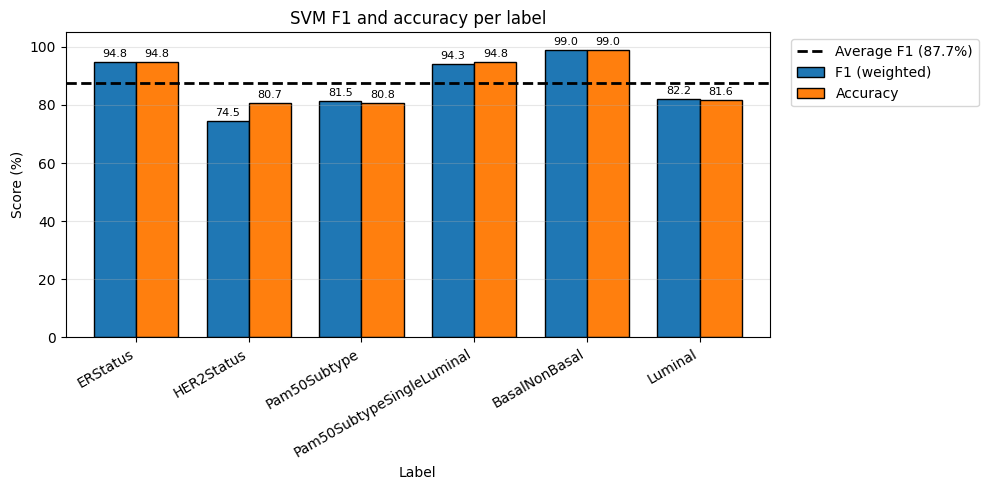

In [12]:
import matplotlib.pyplot as plt

plot_df = results_df.loc[label_names] * 100   # per-label rows only, in percent
avg_f1 = results_df.loc['Average', 'F1 (weighted)'] * 100

ax = plot_df.plot(kind='bar', figsize=(10, 5), width=0.75, edgecolor='black')
ax.axhline(avg_f1, color='black', linestyle='--', linewidth=2,
           label=f'Average F1 ({avg_f1:.1f}%)')

# Value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=2, fontsize=8)

ax.set_xlabel('Label')
ax.set_ylabel('Score (%)')
ax.set_title('SVM F1 and accuracy per label')
ax.set_ylim(0, 105)
ax.set_xticklabels(label_names, rotation=30, ha='right')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()